## 1: Imports and Parameters
Install and import the necessary libraries (numpy, pandas, networkx, pyplot) and define the main parameters of the model

In [ ]:
# Install the libraries

%pip install numpy
%pip install pandas 
%pip install networkx
%pip install matplotlib


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the libraries

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


In [110]:
# Define the main parameters

# Number of nodes
N = 10000

# Parameter c (average number of links for each node)
c = 0.95

# Parameter p (probability that a node is linked to another)
p = c/N

# Parameter lambda (proxy for market depth)
lam = 1

## 2: Random Graph Generation
Generate the Random Graph with the parameters above

In [28]:
G = nx.fast_gnp_random_graph(N, p)

In [29]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Average degree:", sum(dict(G.degree()).values())/N) 

Number of nodes: 10000
Number of edges: 4752
Average degree: 0.9504


## 3: Connected Components Identification
Identification of the graphs connected components

In [30]:
# Visualize the graph's connected components

components = list(nx.connected_components(G))
n_components = len(components)  

print("Number of connected components:", n_components)

cluster_sizes = []

for component in components:
    cluster_sizes.append(len(component))

print("Sizes of connected components:", cluster_sizes)
print("Average size of connected components:", np.mean(cluster_sizes))
print("Largest connected component size:", max(cluster_sizes))

#Check
#print("Sum of sizes of connected components:", sum(cluster_sizes))


Number of connected components: 5249
Sizes of connected components: [2, 70, 13, 11, 59, 5, 1, 12, 1, 8, 1, 1, 16, 4, 116, 2, 1, 2, 3, 16, 1, 66, 25, 12, 1, 3, 1, 1, 1, 1, 5, 5, 1, 6, 28, 2, 1, 2, 31, 2, 30, 1, 1, 15, 12, 1, 1, 1, 8, 1, 2, 3, 6, 58, 3, 12, 1, 1, 17, 3, 2, 1, 6, 1, 14, 1, 1, 7, 2, 5, 1, 2, 1, 1, 1, 1, 7, 7, 3, 2, 7, 2, 1, 5, 2, 9, 1, 1, 22, 13, 2, 1, 3, 3, 4, 1, 6, 1, 9, 1, 2, 13, 57, 37, 1, 1, 30, 3, 13, 3, 1, 1, 26, 41, 2, 9, 3, 16, 3, 2, 2, 2, 1, 1, 1, 3, 6, 4, 1, 2, 3, 1, 2, 1, 2, 2, 7, 6, 1, 16, 5, 1, 1, 1, 2, 28, 1, 1, 6, 1, 1, 2, 17, 2, 1, 11, 2, 3, 1, 4, 1, 1, 31, 8, 1, 1, 1, 1, 1, 9, 1, 2, 2, 10, 2, 8, 14, 1, 1, 1, 1, 2, 16, 1, 10, 1, 2, 3, 5, 1, 2, 17, 1, 1, 1, 2, 1, 4, 1, 1, 7, 15, 1, 2, 1, 1, 4, 1, 1, 1, 1, 1, 5, 1, 2, 1, 1, 2, 6, 1, 8, 1, 1, 1, 1, 2, 1, 3, 1, 1, 2, 1, 1, 5, 1, 3, 3, 2, 1, 2, 18, 45, 1, 1, 1, 1, 4, 1, 1, 2, 1, 1, 1, 1, 1, 4, 2, 1, 1, 7, 1, 1, 1, 1, 66, 10, 1, 1, 8, 1, 1, 1, 1, 15, 1, 17, 2, 1, 1, 3, 1, 1, 4, 1, 2, 1, 1, 1, 1, 1, 1, 1, 6, 7, 1

## 4: One Period Market Simulation
Here we simulate the creation of opinions between clusters, and therefore the market aggregate demand 

In [72]:
# First we need to set the parameter a, s.t. 2a is the prob. that the node is active
# Thus, 0 < a < 0.5

a = 0.4

In [87]:
# Draw decision for each connected component, i.e. if the component is buying,
# selling or inactive

cluster_decisions = np.random.choice([-1, 0, 1], size=n_components, p=[a, 1-2*a, a])

cluster_contributes = cluster_decisions*np.array(cluster_sizes)

#type check
#print(type(cluster_decisions), type (np.array(cluster_sizes)), type(cluster_contributes))

print("Cluster contributes:", cluster_contributes)

D = sum(cluster_contributes)

print("Aggregate demand D:", D)

Cluster contributes: [ -2   0 -13 ...  -1   1   1]
Aggregate demand D: -363


## 5: Repeated experiment
Here we repeat the previous model multiple times

In [5]:
# We now define a functions that computes the one period market simulation 
# and returns the aggregate demand D, given the parameters N, c and a

def one_period_simulation(N, c, a, lam):
    p = c/N
    G = nx.fast_gnp_random_graph(N, p)
    components = list(nx.connected_components(G))
    n_components = len(components)  
    cluster_sizes = [len(component) for component in components]
    cluster_decisions = np.random.choice([-1, 0, 1], size=n_components, p=[a, 1-2*a, a])
    cluster_contributes = cluster_decisions*np.array(cluster_sizes)
    D = sum(cluster_contributes)
    delta_x = D/lam

    results = pd.DataFrame({
        'Price Change': [delta_x],
        'Aggregate Demand': [D],
        'Number of Clusters': [n_components],
        'Active Clusters': [np.sum(abs(cluster_decisions))],
        'Largest Cluster': [max(cluster_sizes)],
    })

    return results

print(one_period_simulation(N, c, a, lam))


   Price Change  Aggregate Demand  Number of Clusters  Active Clusters  \
0         -20.0               -20                 529              220   

   Largest Cluster  
0               41  


In [3]:
# Now we define a function that computes the market simulation for T periods and returns 
# a DataFrame with the results for each period

T = 10_000

N = 1000
c = 0.95
a = 0.2
lam = 1

def market_simulation(T, N, c, a, lam):
    for t in range(T):
        results = one_period_simulation(N, c, a, lam)
        if t == 0:
            df_results = results
        else:
            df_results = pd.concat([df_results, results], ignore_index=True)
    return df_results        

#print(market_simulation(T, N, c, a, lam))

In [126]:
# Let's visualize mean results of the market simulation for T periods

mean_results = market_simulation(T, N, c, a, lam).mean()

In [129]:
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Price Change           -0.9903
Aggregate Demand       -0.9903
Number of Clusters    526.2716
Active Clusters       210.3922
Largest Cluster        68.9804
dtype: float64


## 6: Independent Agent Benchmark

In [130]:
# Now let's simulate the results for c = 0
# This simulates the case where there are no links between the nodes, 
# i.e. each node is isolated and makes its own decision independently of the others

c = 0

mean_results = market_simulation(T, N, c, a, lam).mean()
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Price Change             0.0951
Aggregate Demand         0.0951
Number of Clusters    1000.0000
Active Clusters        400.4487
Largest Cluster          1.0000
dtype: float64


## 7: Effect of c 

In [131]:
# Now let's simulate what happens when c is higher than the critical value 1,
# i.e., when the nodes are connected to more than one other node on average

c = 1.5

mean_results = market_simulation(T, N, c, a, lam).mean()
print(f"Mean results over {T:,} periods:\n")
print(mean_results)

Mean results over 10,000 periods:

Price Change           -6.1257
Aggregate Demand       -6.1257
Number of Clusters    288.1729
Active Clusters       115.1403
Largest Cluster       578.4492
dtype: float64


## 8: Return distribution
In this section we analyze the distribution of returns in the Cont-Bucheaud model, and we compare it with the normally distributed returns we would expect from classical theory

In [6]:
T = 10_000

N = 1000
c = 0.95
a = 0.2
lam = 1

results = market_simulation(T, N, c, a, lam)

returns = results['Price Change'].values

print(results.describe())

       Price Change  Aggregate Demand  Number of Clusters  Active Clusters  \
count  10000.000000      10000.000000        10000.000000     10000.000000   
mean      -0.773800         -0.773800          526.054400       210.293900   
std       67.375151         67.375151           21.410518        14.214349   
min     -313.000000       -313.000000          434.000000       162.000000   
25%      -41.000000        -41.000000          512.000000       200.000000   
50%        0.000000          0.000000          526.000000       210.000000   
75%       40.000000         40.000000          541.000000       220.000000   
max      281.000000        281.000000          605.000000       270.000000   

       Largest Cluster  
count     10000.000000  
mean         68.960900  
std          37.364523  
min          12.000000  
25%          42.000000  
50%          59.000000  
75%          85.000000  
max         317.000000  


In [ ]:
# Let's compute the excess kurtosis of the returns distribution

print("Excess kurtosis of the returns distribution:", pd.Series(returns).kurt())

# An excess kurtosis greater than 0 indicates that the distribution has heavier tails 
# than a normal distribution, which is a common feature of financial returns.

Excess kurtosis of the returns distribution: 0.8021076097954012


Text(0, 0.5, 'Density')

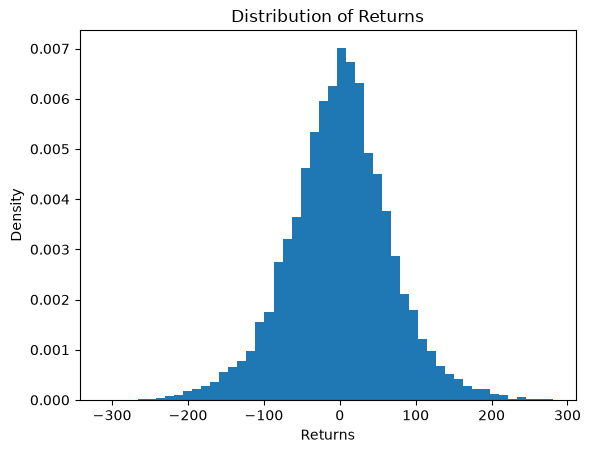

In [11]:
# Now let's visualize the distribution of returns for the market simulation

#plt.figure()

plt.hist(returns, bins=50, density=True)
plt.title("Distribution of Returns")
plt.xlabel("Returns")
plt.ylabel("Density")

#plt.show()

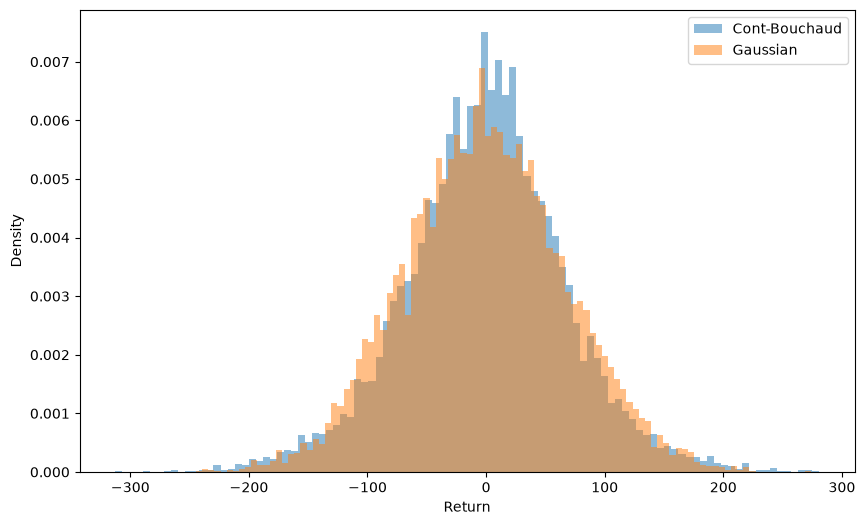

In [ ]:
# Let's compare it to a normal distribution with the same mean and standard deviation

# Lets generate a normal distribution with the same mean and standard deviation as the returns
gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
)

# Now let's plot them together

plt.figure(figsize=(10, 6))

plt.hist(
    returns,
    bins=100,
    density=True,
    alpha=0.5,
    label="Cont-Bouchaud"
)

plt.hist(
    gaussian_returns,
    bins=100,
    density=True,
    alpha=0.5,
    label="Gaussian"
)

plt.xlabel("Return")
plt.ylabel("Density")
plt.legend()
plt.show()


In [ ]:
# Let's better visualize the tails of the distribution by confronting
# the empirical quatiles of the absolute returns of the two models

returns_abs = np.abs(returns)
gaussian_returns_abs = np.abs(gaussian_returns)

returns_quantiles = np.quantile(returns_abs, [0.9, 0.95, 0.99, 0.999])
gaussian_returns_quantiles = np.quantile(gaussian_returns_abs, [0.9, 0.95, 0.99, 0.999])   

print("Empirical quantiles of the absolute returns of the Cont-Bouchaud model:", returns_quantiles)
print(f"Empirical quantiles of the absolute returns of the Gaussian model: {gaussian_returns_quantiles}")


Empirical quantiles of the absolute returns of the Cont-Bouchaud model: [110. 139. 193.]
Empirical quantiles of the absolute returns of the Gaussian model: [111.37953379 131.59057338 175.44189705]


In [28]:
# Now let's see how the tails change when we increase the parameter c, 
# and compare them to the Gaussian model with the same mean and standard deviation

c_values = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]

for c in c_values:
    results = market_simulation(T, N, c, a, lam)
    returns = results['Price Change'].values
    returns_abs = np.abs(returns)
    returns_quantiles = np.quantile(returns_abs, [0.9, 0.95, 0.99, 0.999])

    gaussian_returns = np.random.normal(
    loc=returns.mean(),
    scale=returns.std(),
    size=len(returns)
)
    gaussian_returns_quantiles = np.quantile(np.abs(gaussian_returns), [0.9, 0.95, 0.99, 0.999])

    print(f"Quantiles of the absolute returns of the Cont-Bouchaud model for c={c}: {returns_quantiles}")
    print(f"Quantiles of the absolute returns of the Gaussian model for c={c}: {gaussian_returns_quantiles}\n")

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.5: [46. 55. 72. 91.]
Quantiles of the absolute returns of the Gaussian model for c=0.5: [46.63641267 55.81763113 74.20431869 92.7275757 ]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.75: [ 66.     78.    103.    128.003]
Quantiles of the absolute returns of the Gaussian model for c=0.75: [ 65.09311993  78.26649184 103.25718421 130.35682684]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.9: [ 93.    115.    160.    203.003]
Quantiles of the absolute returns of the Gaussian model for c=0.9: [ 93.01513545 111.66441874 145.37781178 191.23222589]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.95: [112.    140.    198.    264.003]
Quantiles of the absolute returns of the Gaussian model for c=0.95: [111.70115427 132.47309164 173.74829708 217.78241152]

Quantiles of the absolute returns of the Cont-Bouchaud model for c=0.99: [133.    167.    236.01  299.00